In [1]:
import numpy as np
import pandas as pd

In [39]:
from sklearn.datasets import load_wine

In [40]:
load_wine().feature_names

['alcohol',
 'malic_acid',
 'ash',
 'alcalinity_of_ash',
 'magnesium',
 'total_phenols',
 'flavanoids',
 'nonflavanoid_phenols',
 'proanthocyanins',
 'color_intensity',
 'hue',
 'od280/od315_of_diluted_wines',
 'proline']

In [41]:
df = pd.DataFrame(load_wine().data, columns=load_wine().feature_names)

In [42]:
df['target'] = load_wine().target

In [43]:
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [46]:
X = df.drop('target',axis=1)

In [47]:
y = df.target

In [48]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectFromModel

In [49]:
y

0      0
1      0
2      0
3      0
4      0
      ..
173    2
174    2
175    2
176    2
177    2
Name: target, Length: 178, dtype: int32

In [50]:
df['target'].value_counts()

target
1    71
0    59
2    48
Name: count, dtype: int64

In [51]:
rf = RandomForestClassifier(n_estimators=1000, max_depth= None , random_state=42)

In [52]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [53]:
rf.fit(X_train, y_train)

RandomForestClassifier(n_estimators=1000, random_state=42)

In [54]:
y_pred = rf.predict(X_test)

In [55]:
y_pred

array([0, 0, 2, 0, 1, 0, 1, 2, 1, 2, 0, 2, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 2, 2, 2, 1, 1, 1, 0, 0, 1, 2, 0, 0, 0])

In [56]:
from sklearn.metrics import confusion_matrix, accuracy_score

In [57]:
print(confusion_matrix(y_test, y_pred))

[[14  0  0]
 [ 0 14  0]
 [ 0  0  8]]


In [58]:
accuracy_score(y_test, y_pred)

1.0

In [59]:
model = SelectFromModel(rf, prefit=True)

In [60]:
model.get_support()

array([ True, False, False, False, False, False,  True, False, False,
        True,  True,  True,  True])

In [63]:
# Get selected feature names from X (not df)
selected_features = X.columns[model.get_support()]
df[selected_features]

,alcohol,flavanoids,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,3.06,5.64,1.04,3.92,1065.0
1,13.20,2.76,4.38,1.05,3.40,1050.0
2,13.16,3.24,5.68,1.03,3.17,1185.0
3,14.37,3.49,7.80,0.86,3.45,1480.0
4,13.24,2.69,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...
173,13.71,0.61,7.70,0.64,1.74,740.0
174,13.40,0.75,7.30,0.70,1.56,750.0
175,13.27,0.69,10.20,0.59,1.56,835.0
176,13.17,0.68,9.30,0.60,1.62,840.0


In [69]:
feature_imp = rf.feature_importances_

In [79]:
df_importance = pd.DataFrame({'columns':load_wine().feature_names, 'importance':feature_imp})

In [80]:
df_importance

,columns,importance
0,alcohol,0.012603
1,malic_acid,0.015922
2,ash,0.023681
3,alcalinity_of_ash,0.029132
4,magnesium,0.030135
5,total_phenols,0.033334
6,flavanoids,0.048764
7,nonflavanoid_phenols,0.077456
8,proanthocyanins,0.108660
9,color_intensity,0.131060


([0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
 [Text(0, 0, 'alcohol'),
  Text(1, 0, 'malic_acid'),
  Text(2, 0, 'ash'),
  Text(3, 0, 'alcalinity_of_ash'),
  Text(4, 0, 'magnesium'),
  Text(5, 0, 'total_phenols'),
  Text(6, 0, 'flavanoids'),
  Text(7, 0, 'nonflavanoid_phenols'),
  Text(8, 0, 'proanthocyanins'),
  Text(9, 0, 'color_intensity'),
  Text(10, 0, 'hue'),
  Text(11, 0, 'od280/od315_of_diluted_wines'),
  Text(12, 0, 'proline')])

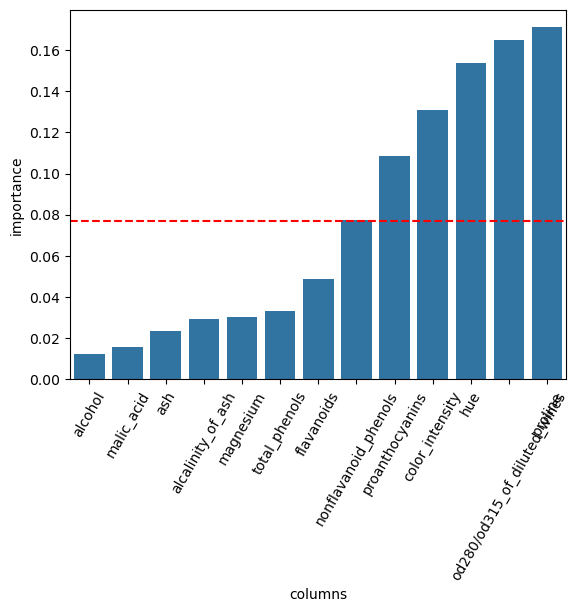

In [90]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.barplot(data = df_importance, x = 'columns', y = 'importance')
plt.axhline(y = feature_imp.mean(), c = 'red',linestyle = '--')
plt.xticks(rotation=60)  # 45 degree

In [91]:
df_selected

,alcohol,flavanoids,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,3.06,5.64,1.04,3.92,1065.0
1,13.20,2.76,4.38,1.05,3.40,1050.0
2,13.16,3.24,5.68,1.03,3.17,1185.0
3,14.37,3.49,7.80,0.86,3.45,1480.0
4,13.24,2.69,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...
173,13.71,0.61,7.70,0.64,1.74,740.0
174,13.40,0.75,7.30,0.70,1.56,750.0
175,13.27,0.69,10.20,0.59,1.56,835.0
176,13.17,0.68,9.30,0.60,1.62,840.0
